In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Stratified Dataset Split (70% Train / 15% Val / 15% Test)
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 4. Image Preprocessing Transformation (No Augmentation)
# ================================================================
base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

def load_image(path, transform=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return vgg_preprocess(img.astype(np.float32))

# ================================================================
# 5. Data Generator Class
# ================================================================
class VGG16OnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = VGG16OnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=True)
val_gen = VGG16OnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)
test_gen = VGG16OnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)

# ================================================================
# 6. Build VGG16 Only Model
# ================================================================
def build_vgg16_only(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # VGG16 Backbone
    base_model = VGG16(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
   # x = layers.BatchNormalization()(x)
   # x = layers.Dropout(0.3)(x)
   # x = layers.Dense(256, activation='relu')(x)
   # x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='VGG16_Only')
    return model, base_model

model, base_model = build_vgg16_only(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "vgg16_only_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting VGG16 Only Training <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 18525.84it/s]


Total images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train samples: 7009 | Val samples: 1503 | Test samples: 1503


I0000 00:00:1789055416.516157      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789055416.519428      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_Only"

...


Epoch 16: finished saving model to vgg16_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 632ms/step - accuracy: 0.9165 - loss: 0.2270 - val_accuracy: 0.8157 - val_loss: 0.5489 - learning_rate: 5.0000e-05
Epoch 17/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.9393 - loss: 0.1692
Epoch 17: val_accuracy did not improve from 0.81570
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 630ms/step - accuracy: 0.9374 - loss: 0.1722 - val_accuracy: 0.8150 - val_loss: 0.7372 - learning_rate: 5.0000e-05
Epoch 18/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - accuracy: 0.9494 - loss: 0.1397
Epoch 18: val_accuracy improved from 0.81570 to 0.81903, saving model to vgg16_only_best.h5



Epoch 18: finished saving model to vgg16_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 140s 635ms/step - accuracy: 0.9502 - loss: 0.1303 - val_accuracy: 0.8190 - val_loss: 0.6849 - learning_rate: 5.0000e-05
Epoch 19/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.9589 - loss: 0.1245
Epoch 19: val_accuracy improved from 0.81903 to 0.82036, saving model to vgg16_only_best.h5



Epoch 19: finished saving model to vgg16_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 140s 635ms/step - accuracy: 0.9484 - loss: 0.1568 - val_accuracy: 0.8204 - val_loss: 0.6234 - learning_rate: 5.0000e-05
Epoch 20/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.9699 - loss: 0.0801
Epoch 20: val_accuracy improved from 0.82036 to 0.82568, saving model to vgg16_only_best.h5



Epoch 20: finished saving model to vgg16_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 140s 637ms/step - accuracy: 0.9689 - loss: 0.0814 - val_accuracy: 0.8257 - val_loss: 0.7833 - learning_rate: 5.0000e-05
Epoch 21/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.9690 - loss: 0.0856
Epoch 21: val_accuracy did not improve from 0.82568

Epoch 21: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 631ms/step - accuracy: 0.9740 - loss: 0.0748 - val_accuracy: 0.8084 - val_loss: 0.8602 - learning_rate: 5.0000e-05
Epoch 22/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.9972 - loss: 0.0191
Epoch 22: val_accuracy improved from 0.82568 to 0.83633, saving model to vgg16_only_best.h5



Epoch 22: finished saving model to vgg16_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 641ms/step - accuracy: 0.9973 - loss: 0.0149 - val_accuracy: 0.8363 - val_loss: 1.0504 - learning_rate: 2.5000e-05
Epoch 23/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.9999 - loss: 0.0049
Epoch 23: val_accuracy did not improve from 0.83633
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 642ms/step - accuracy: 0.9997 - loss: 0.0044 - val_accuracy: 0.8290 - val_loss: 1.1496 - learning_rate: 2.5000e-05
Epoch 24/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 1.0000 - loss: 0.0019
Epoch 24: val_accuracy did not improve from 0.83633
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 639ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.8317 - val_loss: 1.2592 - learning_rate: 2.5000e-05
Epoch 25/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - accuracy: 1.0000 - loss: 0.0011
Epoch 25: val_accuracy did not improve from 0.83633
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 640ms/step - accuracy: 1.0000 - loss: 0.0

Test Accuracy: 83.23%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.6286    0.4490    0.5238        49
         bcc     0.7746    0.7143    0.7432        77
         bkl     0.7152    0.6545    0.6835       165
          df     0.6923    0.5294    0.6000        17
         mel     0.6412    0.5030    0.5638       167
          nv     0.8858    0.9483    0.9160      1006
        vasc     0.7600    0.8636    0.8085        22

    accuracy                         0.8323      1503
   macro avg     0.7283    0.6660    0.6913      1503
weighted avg     0.8218    0.8323    0.8245      1503



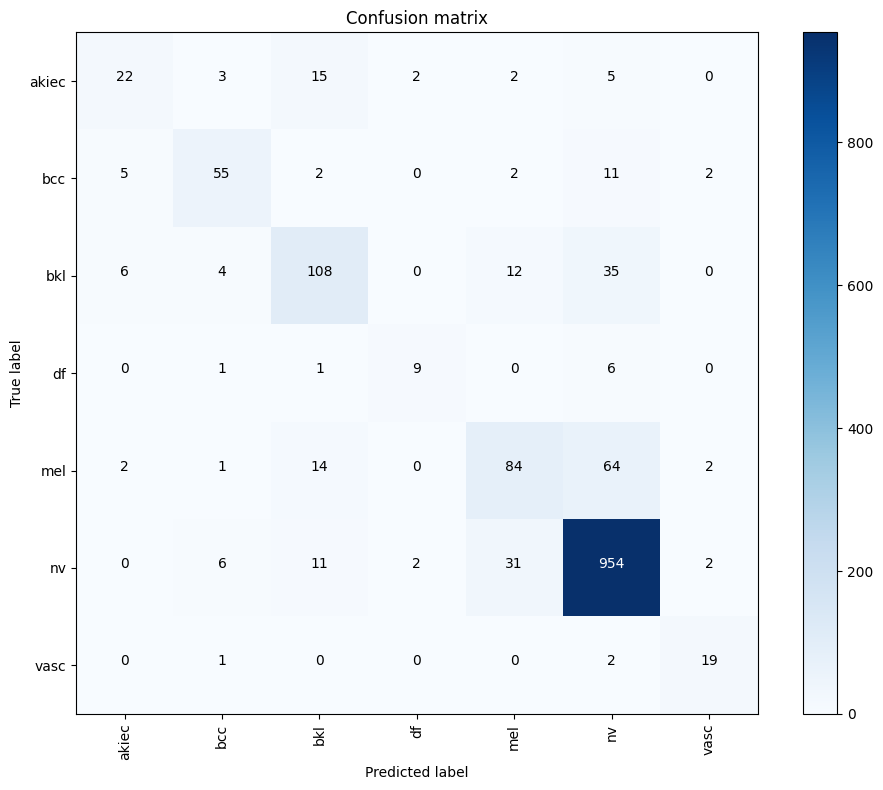

In [2]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

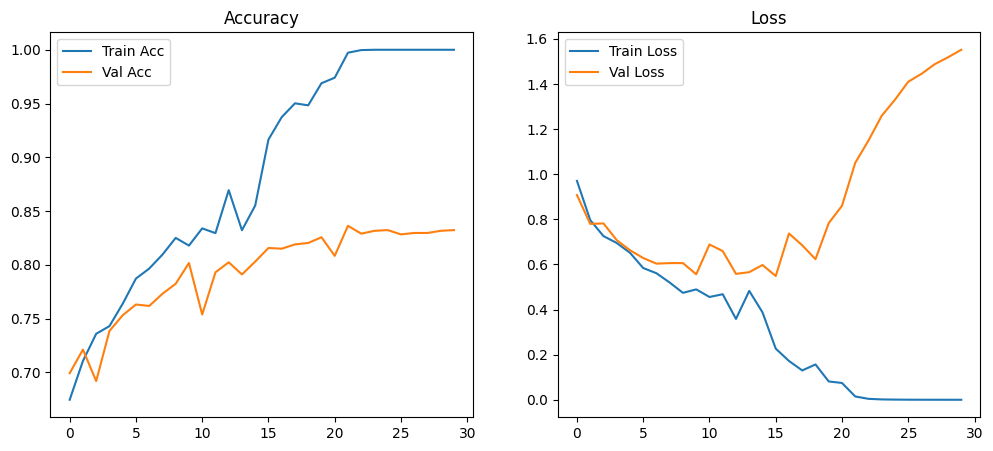

In [3]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

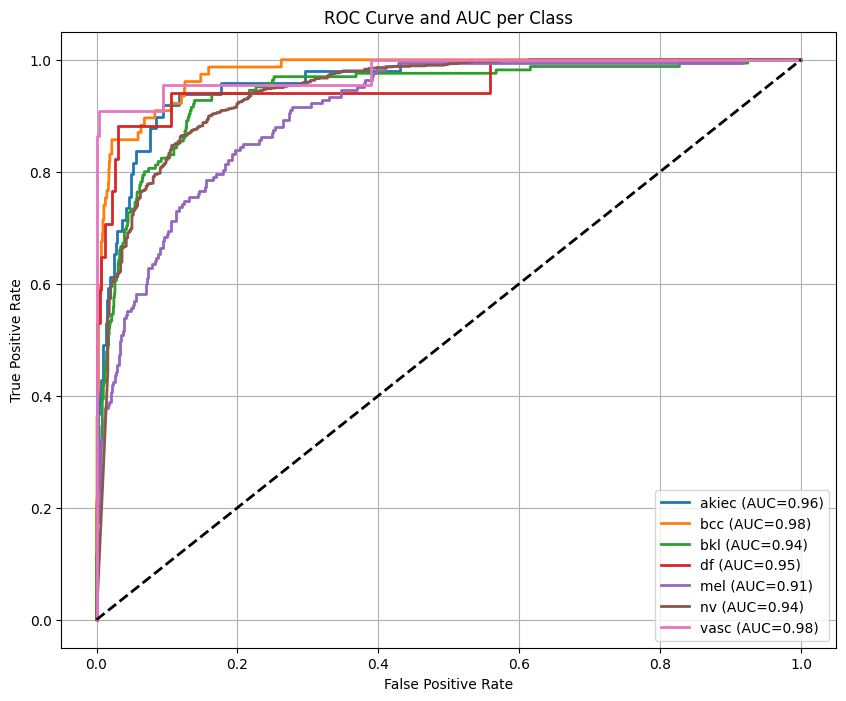

AUC for akiec: 0.9605
AUC for bcc: 0.9789
AUC for bkl: 0.9422
AUC for df: 0.9549
AUC for mel: 0.9074
AUC for nv: 0.9429
AUC for vasc: 0.9777
weighted-average AUC: 0.9788


In [4]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [5]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 83.23%
 Specificity : 95.12%
 Precision   : 82.18%
 Sensitivity : 83.23%
 F1 Score    : 82.45%
